lab7
\
jaber alsaikhan
\
2240006539

# ARTI 404 - Image Processing
## Lab 7: Laplacian Filter, and Mathematical & Statistical Filters

The lab has two parts:

- **Part A** sharpens an image with the Laplacian filter, first with a manually
  defined kernel and `cv2.filter2D`, then with `cv2.Laplacian`.
- **Part B** adds four kinds of noise to an image and removes it with the
  mean filters (arithmetic, geometric, harmonic, contra-harmonic) and the
  order-statistic filters (median, max, min, midpoint).

The images the manual reads (`moon.jpg` and `noise.jpg`), plus a real
salt-and-pepper image used for the median filter, are in `labs/lab7/images/`.

In [1]:
import os

import cv2
import numpy as np
from matplotlib import pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr

plt.rc('text', usetex=False)
# Noisy images compress badly as PNG, so figures are embedded as JPEG to keep
# the notebook small.
%config InlineBackend.figure_formats = ['jpeg']

IMAGES_DIR = "images"
for f in sorted(os.listdir(IMAGES_DIR)):
    im = cv2.imread(os.path.join(IMAGES_DIR, f), 0)
    print(f"{f:16s} {im.shape}")

moon.jpg         (438, 401)
noise.jpg        (506, 508)
salt_pepper.jpg  (224, 225)


# Part A: Laplacian Filter

The Laplacian is the second derivative of the image,
`∇²f = ∂²f/∂x² + ∂²f/∂y²`. In discrete form it is the kernel

```
0  1  0
1 -4  1
0  1  0
```

It is 0 in flat regions and has a strong positive/negative response on both
sides of every edge, so it highlights fine detail. Adding that detail back to
the original image sharpens it.

## Apply Laplacian Filter on Image to get Sharp Image

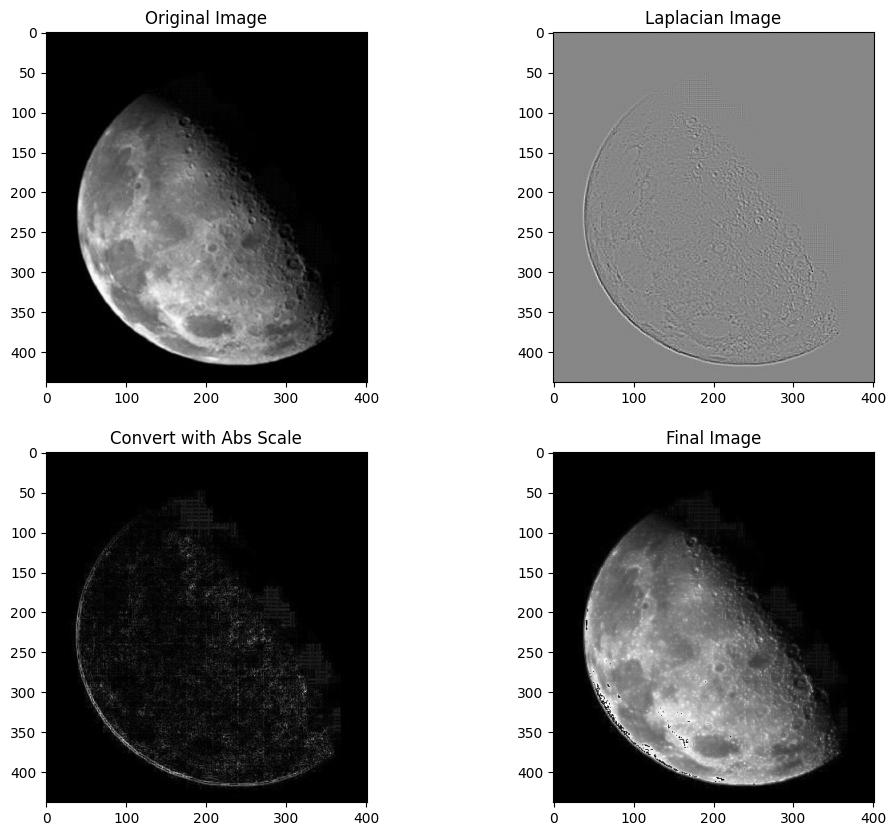

In [2]:
# ================ ( Laplacian Filter ) ===================


# 0. Image file path
imgFile = os.path.join(IMAGES_DIR, "moon.jpg")

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# 3. Apply the filter using filter2D
# For Laplacian, use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

finalImage = img + laplacian_abs

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()

The Laplacian image is mid-gray in flat areas and shows the crater rims as
bright/dark pairs. `convertScaleAbs` keeps only the edge strength.

Two things are wrong with `finalImage = img + laplacian_abs`:

1. **Overflow.** Both arrays are `uint8`, so the sum wraps around modulo 256: a
   bright pixel (200) plus a strong edge (100) becomes 44, not 255. That is why
   some crater rims turn black in the final image.
2. **Sign.** Taking the absolute value throws away which side of the edge a
   pixel is on, so the image is only brightened along edges. Sharpening needs
   the dark side of an edge to get darker *and* the bright side brighter.
   Because the centre coefficient of this kernel is negative, the correct
   formula is `g = f - ∇²f`.

Pixels that overflowed in img + laplacian_abs: 541 (0.31% of the image)


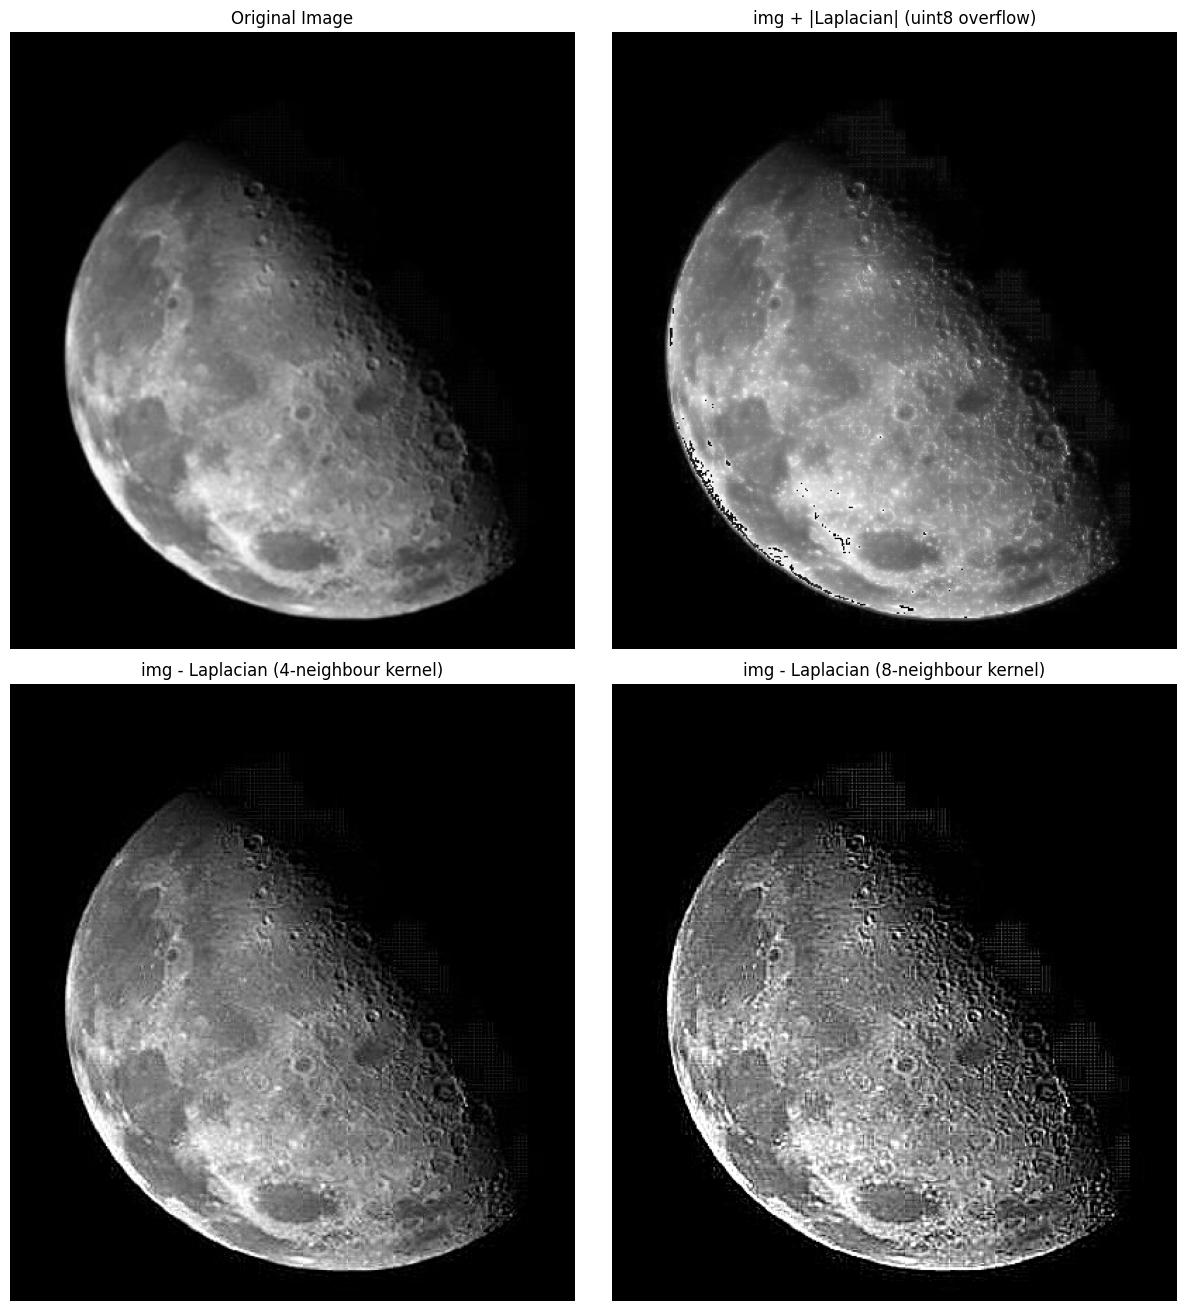

In [3]:
wrapped = (img.astype(np.int32) + laplacian_abs) > 255
print(f"Pixels that overflowed in img + laplacian_abs: {wrapped.sum()} "
      f"({100 * wrapped.mean():.2f}% of the image)")

# Correct sharpening: work in float, subtract the signed Laplacian, then clip.
sharp_4 = np.clip(img.astype(np.float64) - laplacian_manual, 0, 255).astype(np.uint8)

# The alternative kernel from the manual also includes the diagonal neighbours.
kernel_8 = np.array([
    [1,  1,  1],
    [1, -8,  1],
    [1,  1,  1]
], dtype=np.float32)
laplacian_8 = cv2.filter2D(img, cv2.CV_64F, kernel_8)
sharp_8 = np.clip(img.astype(np.float64) - laplacian_8, 0, 255).astype(np.uint8)

fig, ax = plt.subplots(2, 2, figsize=(12, 13), layout="constrained")
ax[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255), ax[0, 0].set_title('Original Image')
ax[0, 1].imshow(finalImage, cmap='gray', vmin=0, vmax=255), ax[0, 1].set_title('img + |Laplacian| (uint8 overflow)')
ax[1, 0].imshow(sharp_4, cmap='gray', vmin=0, vmax=255), ax[1, 0].set_title('img - Laplacian (4-neighbour kernel)')
ax[1, 1].imshow(sharp_8, cmap='gray', vmin=0, vmax=255), ax[1, 1].set_title('img - Laplacian (8-neighbour kernel)')
for a in ax.flat:
    a.axis('off')
plt.show()

With `img - Laplacian` the craters and the terminator (the line between the lit
and dark halves) are clearly sharper, with no black artefacts. The 8-neighbour
kernel also responds to diagonal edges and its centre weight is larger, so it
sharpens more strongly.

### Using `cv2.Laplacian`

The second version blurs the image first: the Laplacian is a second
derivative, so it amplifies noise, and a small Gaussian blur stops it from
treating noise as edges. `cv2.Laplacian` with the default `ksize=1` uses the
same 4-neighbour kernel as above.

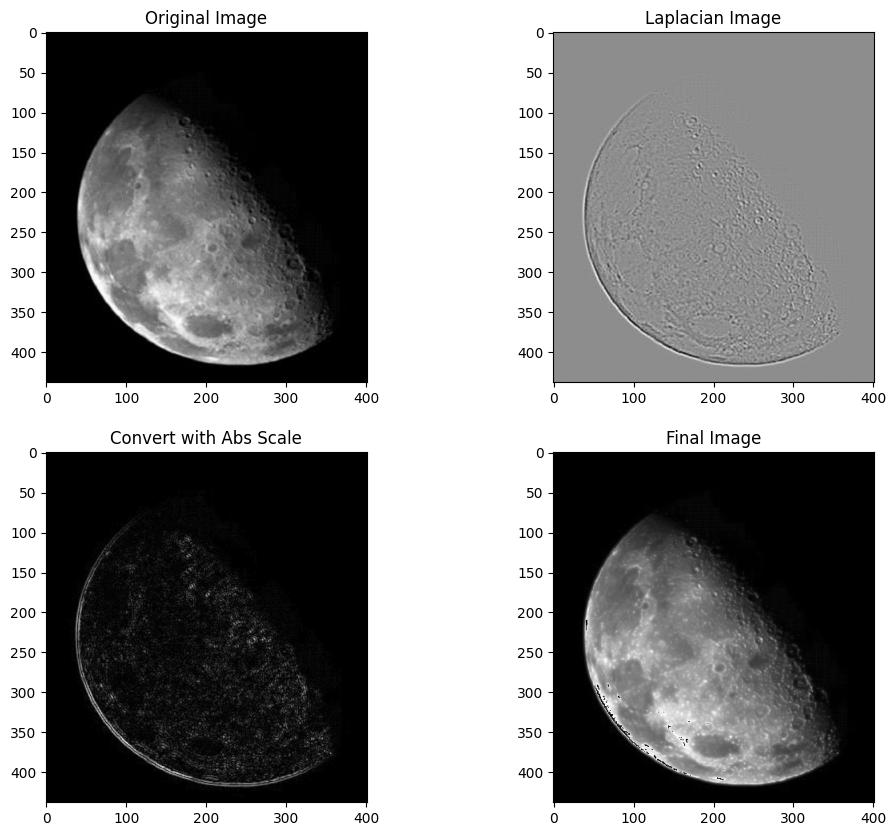

In [4]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and origianl Image
finalImage2 = img + laplacian_8bit

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()

cv2.Laplacian(ksize=1) == filter2D with the 4-neighbour kernel: True


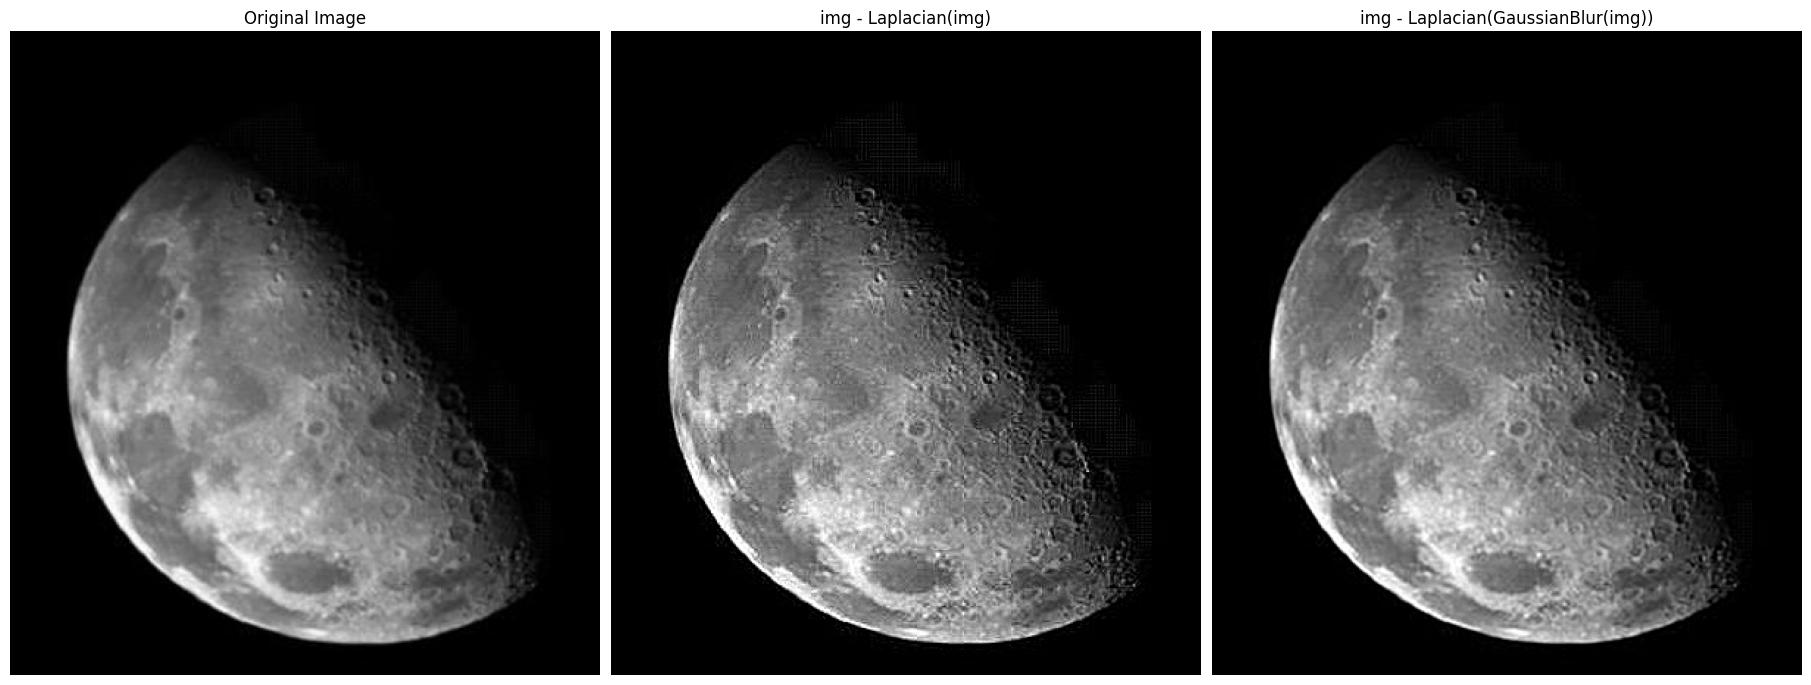

In [5]:
# Same fix as before: subtract the signed Laplacian in float and clip.
sharp_blur = np.clip(img.astype(np.float64) - laplacian, 0, 255).astype(np.uint8)

print("cv2.Laplacian(ksize=1) == filter2D with the 4-neighbour kernel:",
      np.allclose(cv2.Laplacian(img, cv2.CV_64F), laplacian_manual))

fig, ax = plt.subplots(1, 3, figsize=(18, 7), layout="constrained")
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255), ax[0].set_title('Original Image')
ax[1].imshow(sharp_4, cmap='gray', vmin=0, vmax=255), ax[1].set_title('img - Laplacian(img)')
ax[2].imshow(sharp_blur, cmap='gray', vmin=0, vmax=255), ax[2].set_title('img - Laplacian(GaussianBlur(img))')
for a in ax:
    a.axis('off')
plt.show()

Blurring first gives a slightly softer result: the blocky JPEG artefacts in
the dark sky and along the terminator are amplified less, while the crater
edges are still enhanced.

# Part B: Mathematical and Statistical Filters

## Adding noise to an image

`add_noise` from the manual generates four noise models:

| Noise | Model |
| --- | --- |
| Gaussian | `N(0, σ²)` with `σ² = 0.01` on the [0, 1] scale (σ ≈ 25 gray levels) |
| Salt & pepper | 4% of the pixels set to 255 (salt) or 0 (pepper), half each |
| Exponential | `+ Exp(scale=10)`, always positive, so it brightens the image |
| Uniform | `+ U(-20, 20)` |

The random seed is fixed so the results are the same every time the notebook
is run.

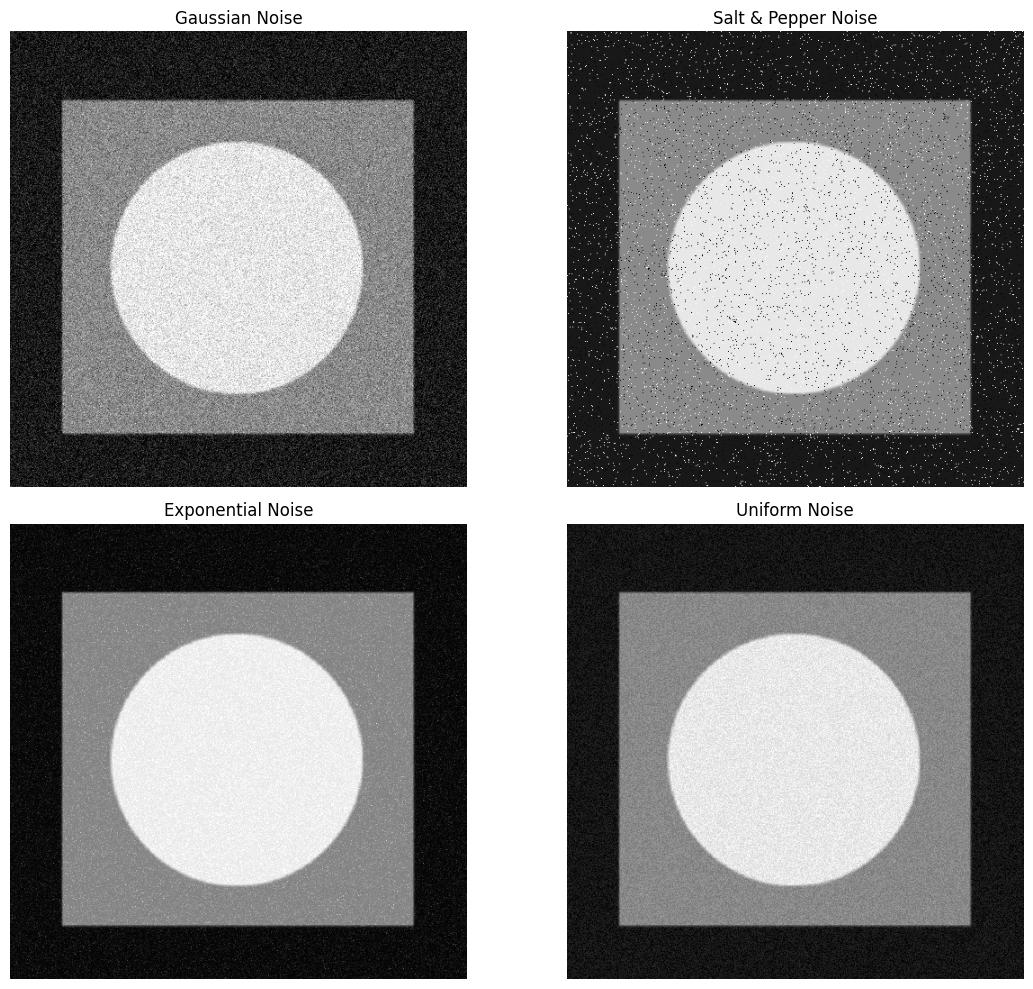

In [6]:
# ========== ( Adding nosie to an Image ) =================

np.random.seed(0)

# 0. Read an Image
imgPath = os.path.join(IMAGES_DIR, 'noise.jpg')
img = cv2.imread(imgPath, 0)

# 1. Function that handle all noise algorithm (Guassian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)


# 2. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 3. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')

for i in range(1, 5):
    plt.subplot(220 + i).axis('off')

plt.tight_layout()
plt.show()

The manual picked coordinates with `np.random.randint(0, i - 1, ...)`. The upper
bound of `randint` is already exclusive, so that never touched the last row or
column; it is `randint(0, i, ...)` here.

The salt-only and pepper-only images below are used later to show which
filters remove which kind of impulse noise. `show` is a small helper so every
comparison is plotted the same way.

In [7]:
def add_impulse(image, value, amount=0.04):
    # Set a fraction `amount` of the pixels to `value` (255 = salt, 0 = pepper).
    noisy = image.copy()
    mask = np.random.rand(*image.shape) < amount
    noisy[mask] = value
    return noisy

noise_salt = add_impulse(img, 255)
noise_pepper = add_impulse(img, 0)


def show(images, titles, size=5):
    fig, ax = plt.subplots(1, len(images), figsize=(size * len(images), size), layout="constrained")
    for a, im, t in zip(ax, images, titles):
        a.imshow(im, cmap='gray', vmin=0, vmax=255)
        a.set_title(t)
        a.axis('off')
    plt.show()


noisy_images = {
    "Gaussian": noise_gauss,
    "Salt & Pepper": noise_sp,
    "Exponential": noise_expo,
    "Uniform": noise_uni,
}
for name, im in noisy_images.items():
    print(f"PSNR of {name:13s} noisy image: {psnr(img, im):.2f} dB")

PSNR of Gaussian      noisy image: 20.87 dB
PSNR of Salt & Pepper noisy image: 18.50 dB
PSNR of Exponential   noisy image: 25.70 dB
PSNR of Uniform       noisy image: 26.88 dB


PSNR (peak signal-to-noise ratio, in dB) compares an image with the clean
original; higher is better. It is used below to measure how much each filter
helps.

## **Arithmetic Mean Filter**

`f̂(x, y) = (1/mn) Σ g(s, t)`: every pixel becomes the average of its `m × n`
neighbourhood. It reduces random noise but also blurs edges.

max |cv2.blur - filter2D| = 0


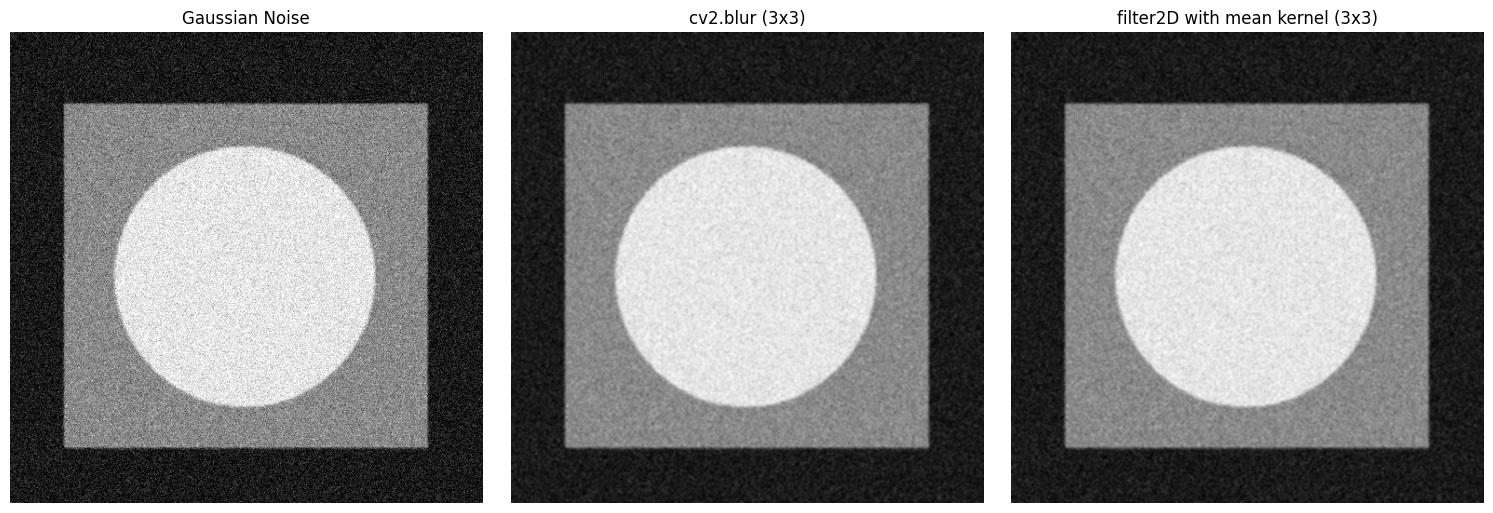

In [8]:
# --- METHOD 1: Using Built-in OpenCV function ---

# Apply Arithmetic Mean Filter (using a 3x3 blur window)
# The larger the numbers in (3, 3), the smoother the image becomes.,
# you can change kernel size to (5,5), (7,7) etc.
filtered_img = cv2.blur(noise_gauss, (3, 3))

# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

print("max |cv2.blur - filter2D| =",
      np.abs(filtered_img.astype(int) - arithmetic_mean_manual).max())

show([noise_gauss, filtered_img, arithmetic_mean_manual],
     ['Gaussian Noise', 'cv2.blur (3x3)', 'filter2D with mean kernel (3x3)'])

The manual's Method 2 filtered `img` (the clean image) instead of the noisy
one; here both methods filter `noise_gauss`, and they give exactly the same
result.

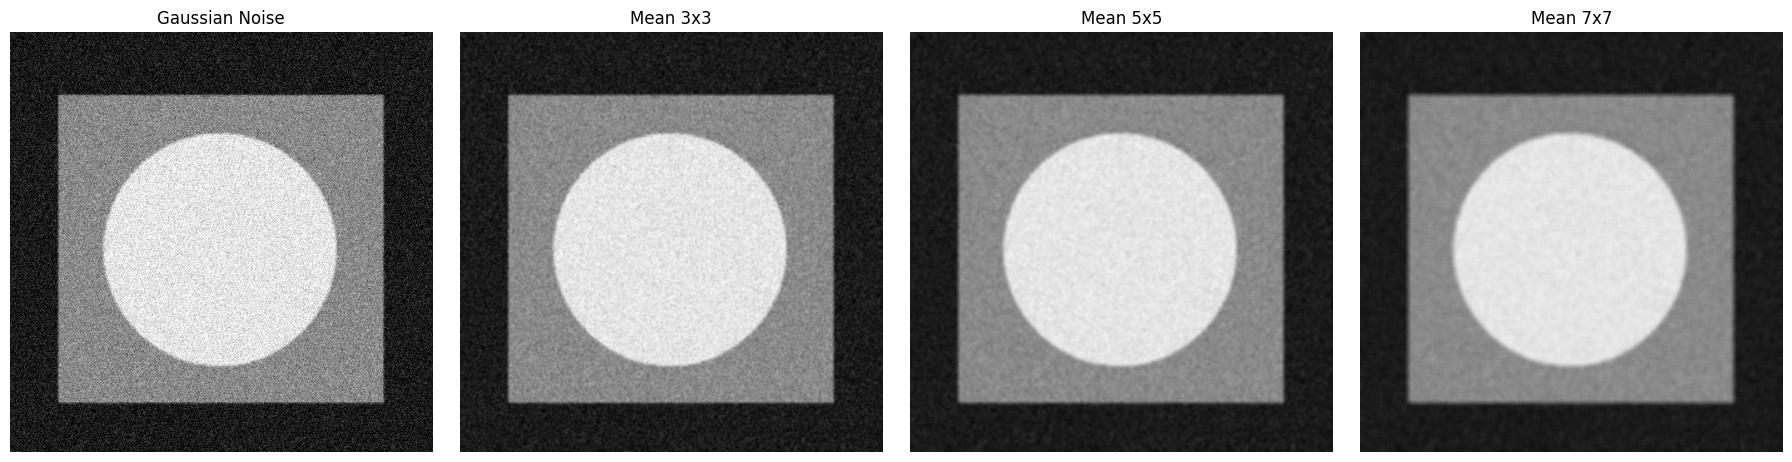

In [9]:
show([noise_gauss] + [cv2.blur(noise_gauss, (k, k)) for k in (3, 5, 7)],
     ['Gaussian Noise', 'Mean 3x3', 'Mean 5x5', 'Mean 7x7'], size=4.5)

A larger window removes more noise but blurs the edges of the square and the
circle more.

## **Geometric Mean Filter**

`f̂(x, y) = [Π g(s, t)]^(1/mn)`. Taking the log turns the product into a sum,
so it is computed as `exp(mean(log g))`. It smooths about as well as the
arithmetic mean but loses less detail. Any 0 in the window makes the product
0, so it is very bad for pepper noise.

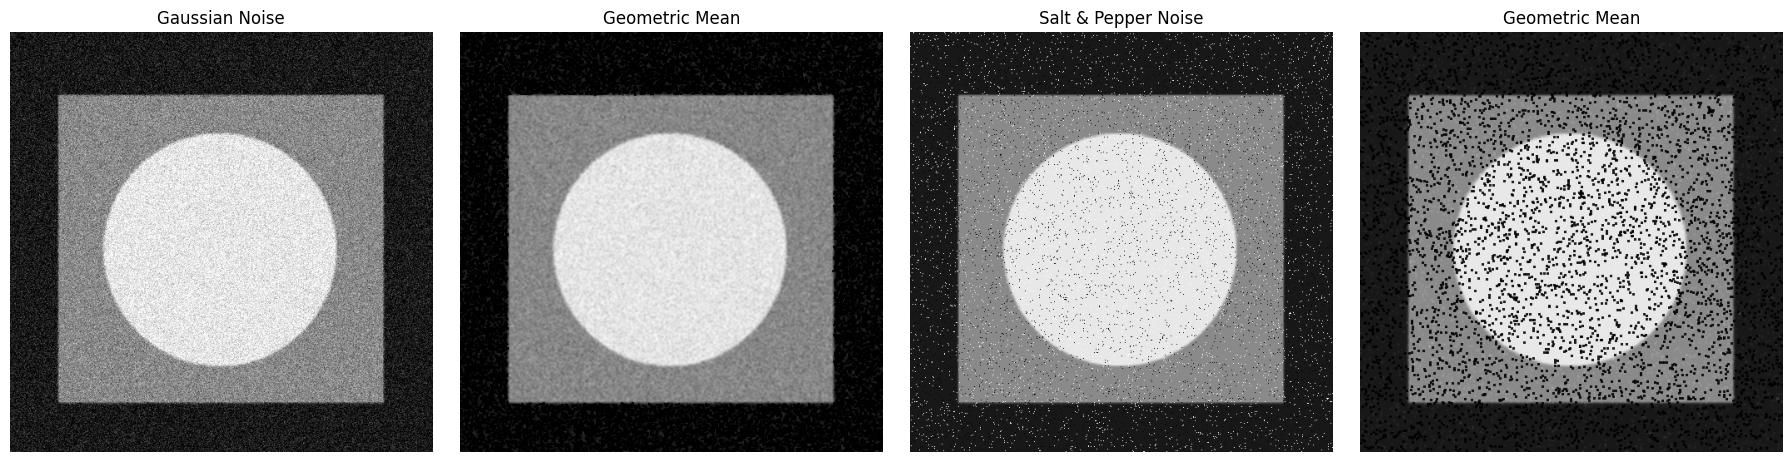

In [10]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


show([noise_gauss, geometric_mean_filter(noise_gauss), noise_sp, geometric_mean_filter(noise_sp)],
     ['Gaussian Noise', 'Geometric Mean', 'Salt & Pepper Noise', 'Geometric Mean'], size=4.5)

On Gaussian noise the bright square and circle are smoothed well, but the dark
background (gray level 24) gets darker: with σ ≈ 25 about 8% of the
noisy pixels are clipped to 0, and a single 0 (→ 1e-6) in a window pulls the
geometric mean down to almost black. On salt & pepper noise the same thing
happens to every pepper pixel, so the black dots grow into black squares.

## **Harmonic Mean Filter**

`f̂(x, y) = mn / Σ (1 / g(s, t))`. It works well for salt noise and Gaussian
noise, but fails on pepper noise: `1/0` dominates the sum.

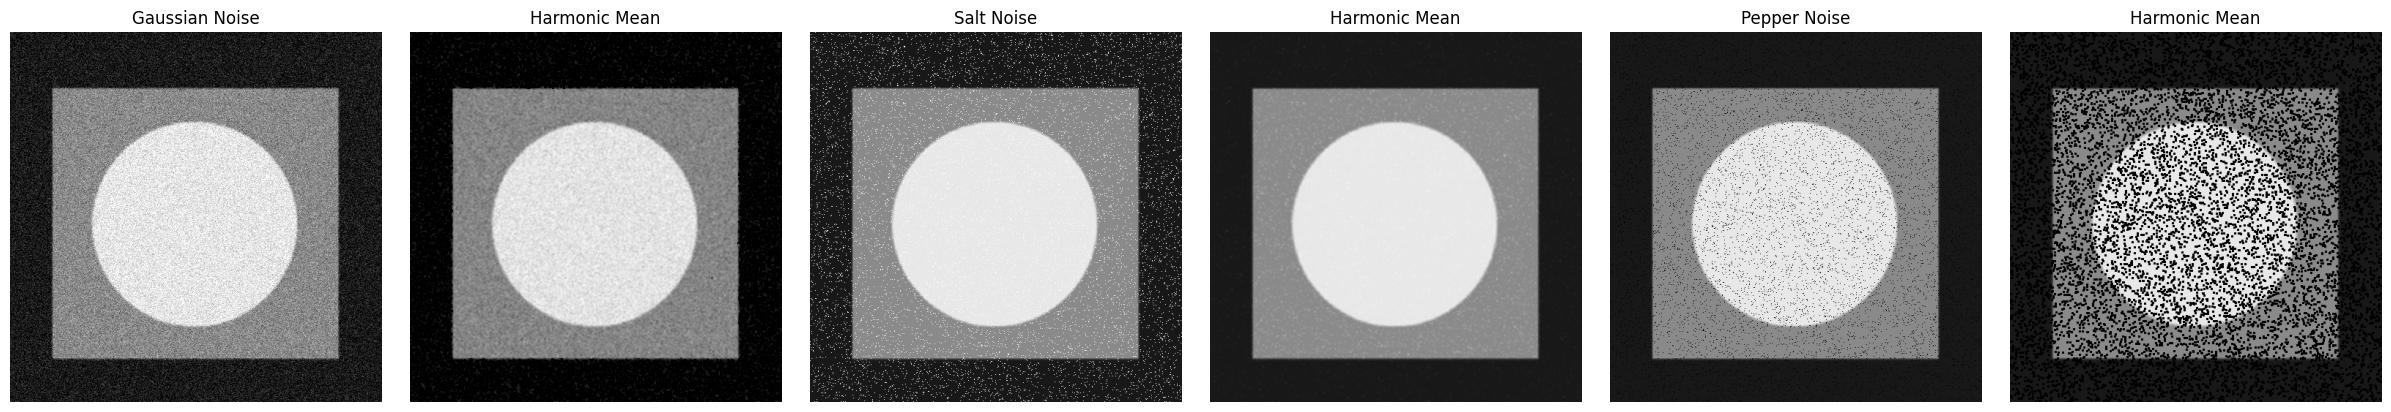

In [11]:
def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


show([noise_gauss, harmonic_mean_filter(noise_gauss),
      noise_salt, harmonic_mean_filter(noise_salt),
      noise_pepper, harmonic_mean_filter(noise_pepper)],
     ['Gaussian Noise', 'Harmonic Mean', 'Salt Noise', 'Harmonic Mean',
      'Pepper Noise', 'Harmonic Mean'], size=4)

The harmonic mean removes the salt noise almost completely (a 255 pixel adds
only 1/255 to the sum of reciprocals) but turns every pepper pixel into a
black square.

## **Contra-Harmonic Mean Filter**

`f̂(x, y) = Σ g(s, t)^(Q+1) / Σ g(s, t)^Q`

- `Q > 0` favours bright values and removes **pepper** noise.
- `Q < 0` favours dark values and removes **salt** noise.
- `Q = 0` is the arithmetic mean and `Q = -1` is the harmonic mean.

It cannot remove both at once, so the manual's version (applied to Gaussian
noise) is shown first, then each `Q` on the noise it is meant for.

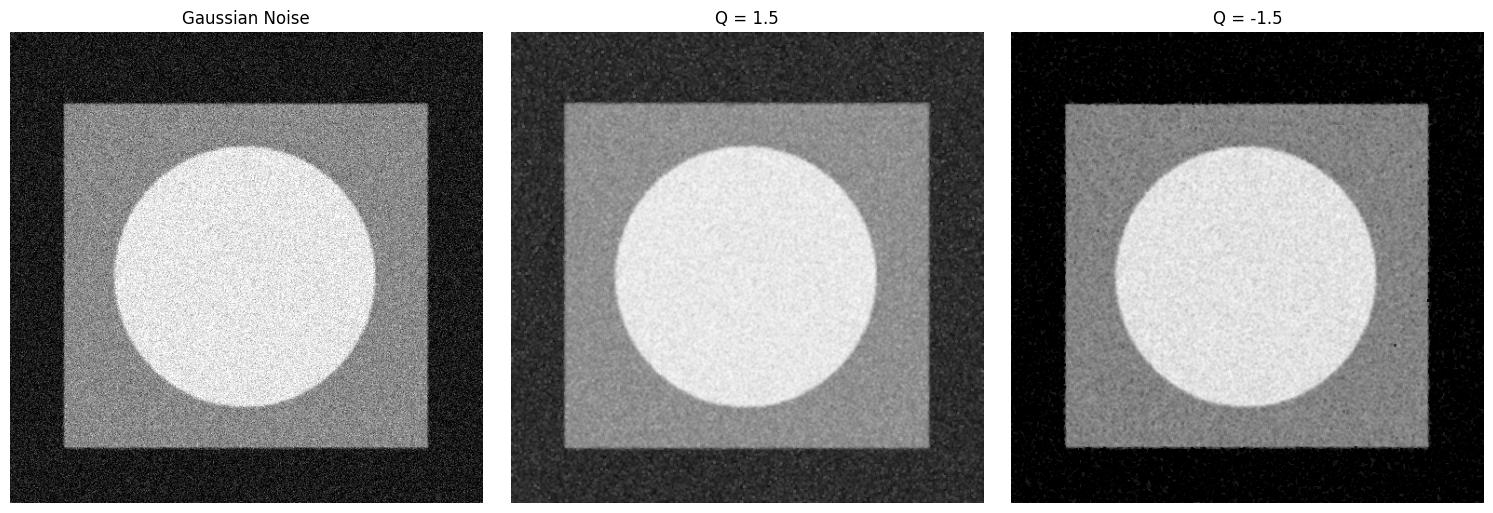

In [12]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)


noise_img = noise_gauss

# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

show([noise_img, pepper_removed, salt_removed],
     ['Gaussian Noise', 'Q = 1.5', 'Q = -1.5'])

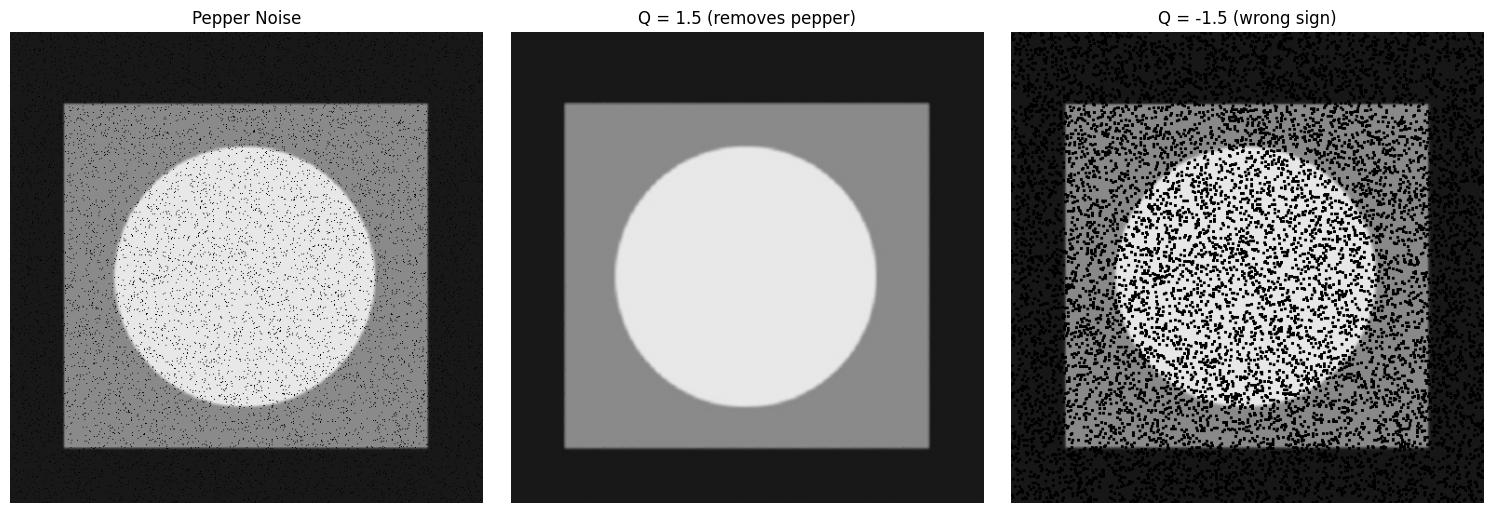

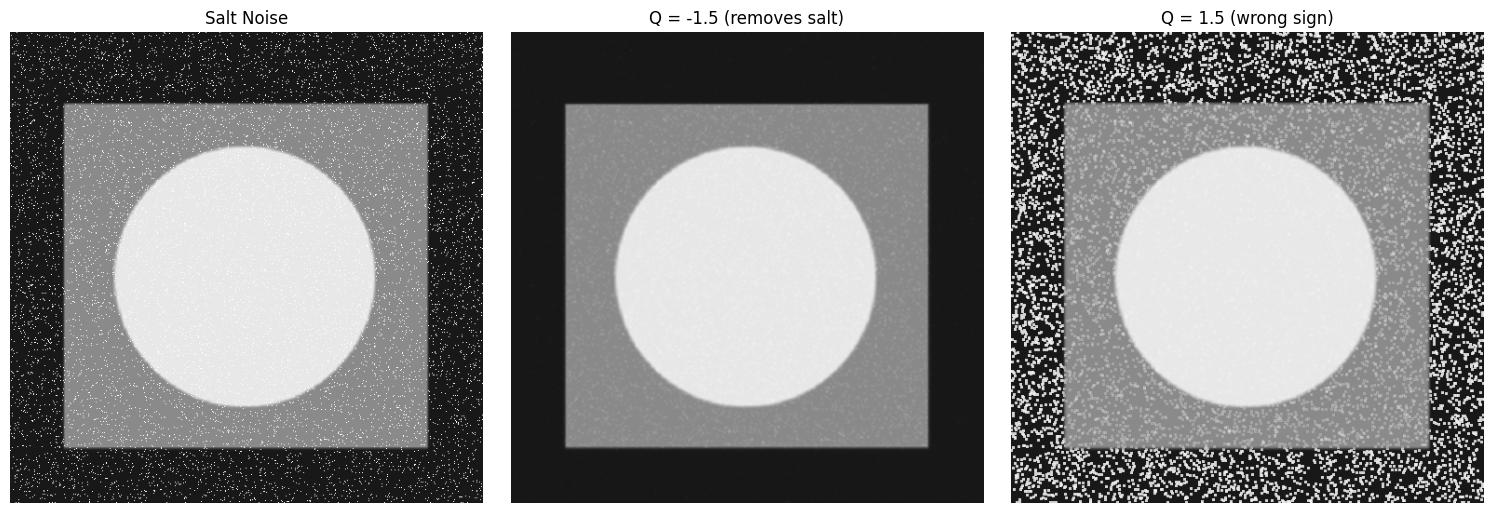

In [13]:
show([noise_pepper, contra_harmonic_mean(noise_pepper, Q=1.5), contra_harmonic_mean(noise_pepper, Q=-1.5)],
     ['Pepper Noise', 'Q = 1.5 (removes pepper)', 'Q = -1.5 (wrong sign)'])
show([noise_salt, contra_harmonic_mean(noise_salt, Q=-1.5), contra_harmonic_mean(noise_salt, Q=1.5)],
     ['Salt Noise', 'Q = -1.5 (removes salt)', 'Q = 1.5 (wrong sign)'])

With the right sign of `Q` the impulse noise disappears; with the wrong sign
each impulse spreads over its whole 3x3 window, which is worse than doing
nothing.

## **Median Filter**

Each pixel is replaced by the median of its neighbourhood. An impulse (0 or
255) is an extreme value, so it is almost never the median: the median filter
removes salt & pepper noise while keeping edges sharp. It is the standard
filter for this kind of noise.

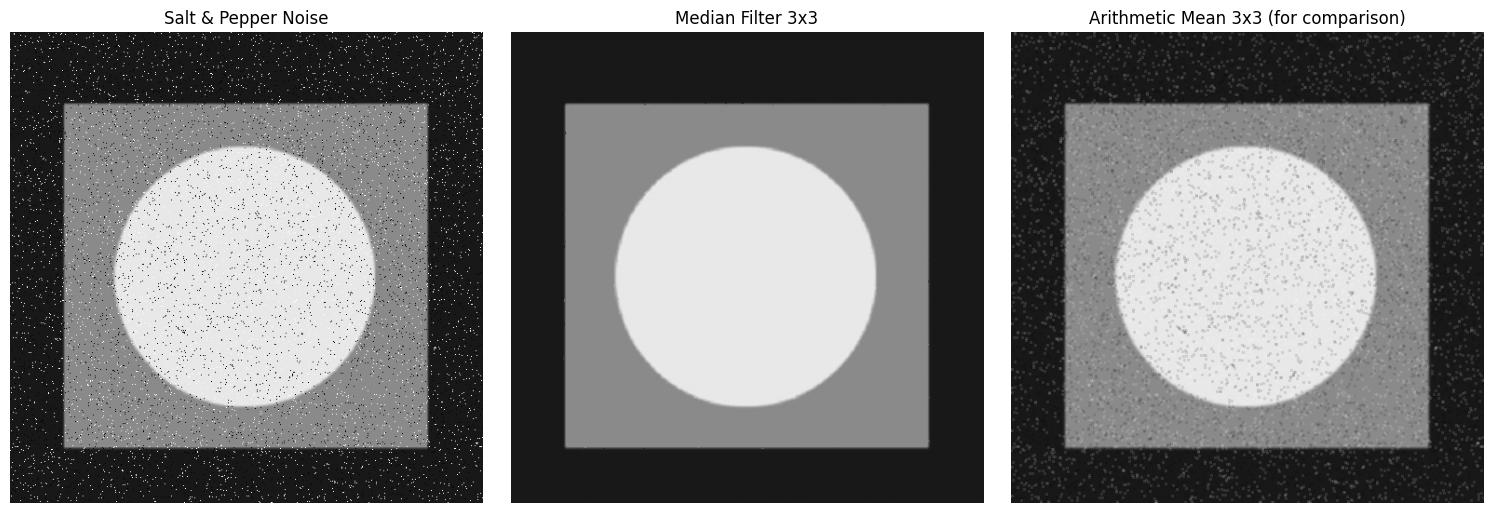

In [14]:
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
show([noise_sp, cv2.medianBlur(noise_sp, 3), cv2.blur(noise_sp, (3, 3))],
     ['Salt & Pepper Noise', 'Median Filter 3x3', 'Arithmetic Mean 3x3 (for comparison)'])

The manual applied the median filter to `noise_gauss` but titled it "Salt &
Pepper Noise"; here it is applied to `noise_sp`. The mean filter only spreads
each impulse into a gray blob, while the median removes it.

The same filter on the real salt-and-pepper photograph from the lab images:

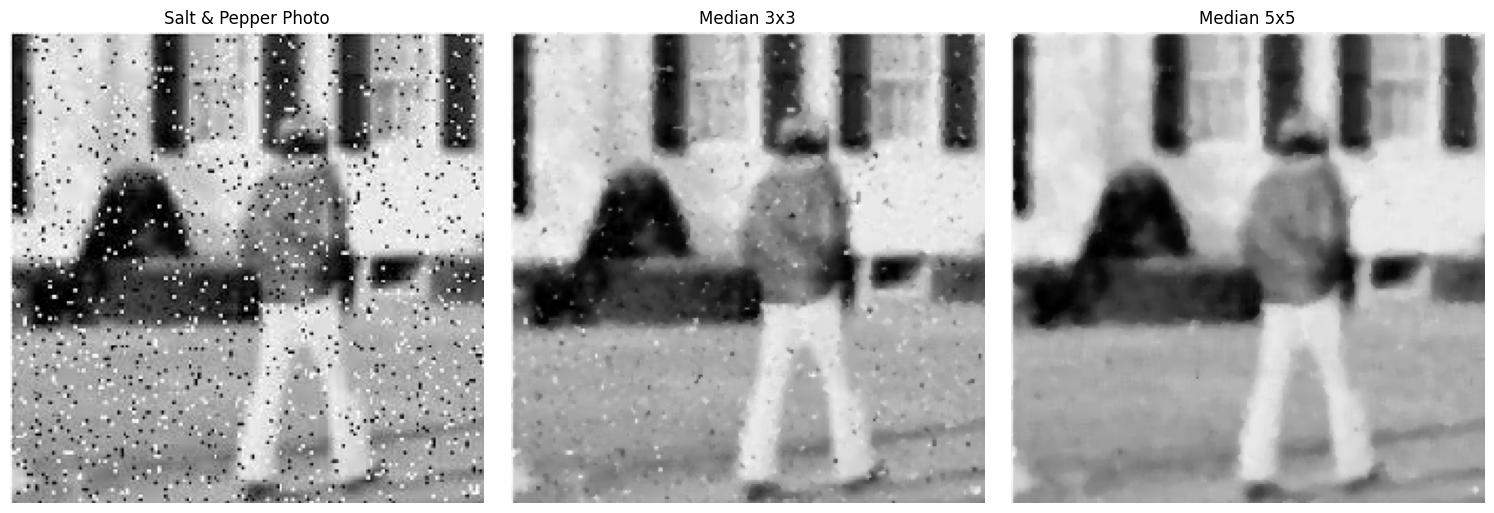

In [15]:
sp_photo = cv2.imread(os.path.join(IMAGES_DIR, 'salt_pepper.jpg'), 0)

show([sp_photo, cv2.medianBlur(sp_photo, 3), cv2.medianBlur(sp_photo, 5)],
     ['Salt & Pepper Photo', 'Median 3x3', 'Median 5x5'])

The noise in this photo is denser than in `noise_sp`, and many of the dots are
2-pixel blobs (the image was enlarged after the noise was added). The 3x3
median removes most of them and keeps the outline of the person and the
building, but a blob survives whenever 5 or more of the 9 pixels in a window
are noise. The 5x5 median removes almost all of them, at the cost of some fine
detail.

## **Max and Min Filters**

- **Max** (`cv2.dilate`): the brightest pixel in the window. Removes **pepper**
  noise, makes salt noise worse.
- **Min** (`cv2.erode`): the darkest pixel in the window. Removes **salt**
  noise, makes pepper noise worse.

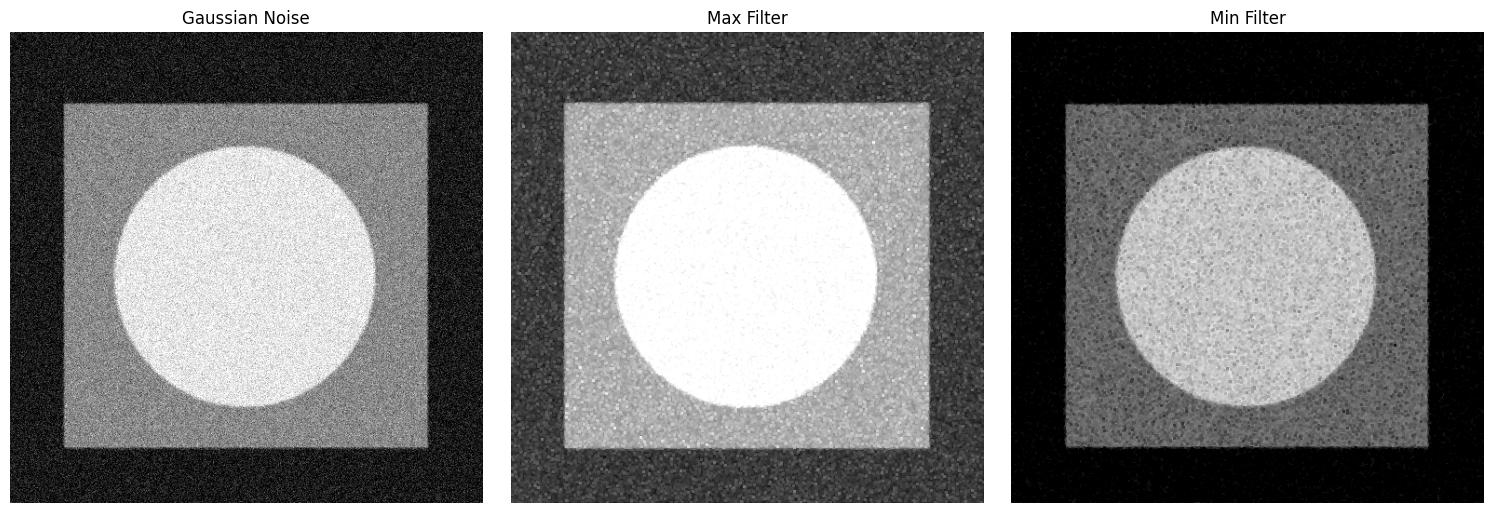

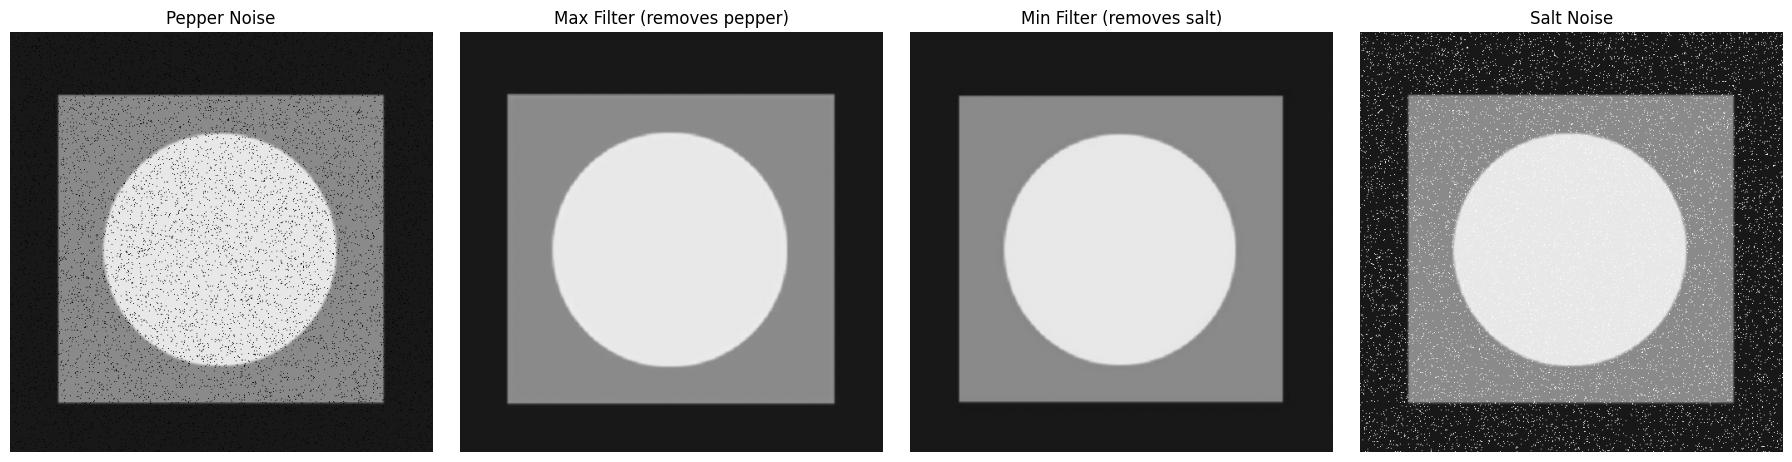

In [16]:
# Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# Max Filter (Dilation): picks the brightest pixel in the neighborhood.
# Min Filter (Erosion): picks the darkest pixel in the neighborhood.
show([noise_gauss, cv2.dilate(noise_gauss, kernel), cv2.erode(noise_gauss, kernel)],
     ['Gaussian Noise', 'Max Filter', 'Min Filter'])
show([noise_pepper, cv2.dilate(noise_pepper, kernel), cv2.erode(noise_salt, kernel), noise_salt],
     ['Pepper Noise', 'Max Filter (removes pepper)', 'Min Filter (removes salt)', 'Salt Noise'], size=4.5)

On Gaussian noise the max filter makes the whole image brighter and the min
filter darker, since every window contains some large positive and negative
noise values. On impulse noise of the matching type they work well, although
the max filter also grows bright regions by one pixel (and the min filter
shrinks them), which can be seen at the edge of the circle.

## **Midpoint Filter**

`f̂(x, y) = (max + min) / 2` over the window. It combines order statistics and
averaging, and works best on randomly distributed noise with a bounded range,
such as Gaussian or uniform noise. It is useless for salt & pepper, where the
max is 255 and the min is 0 in most windows.

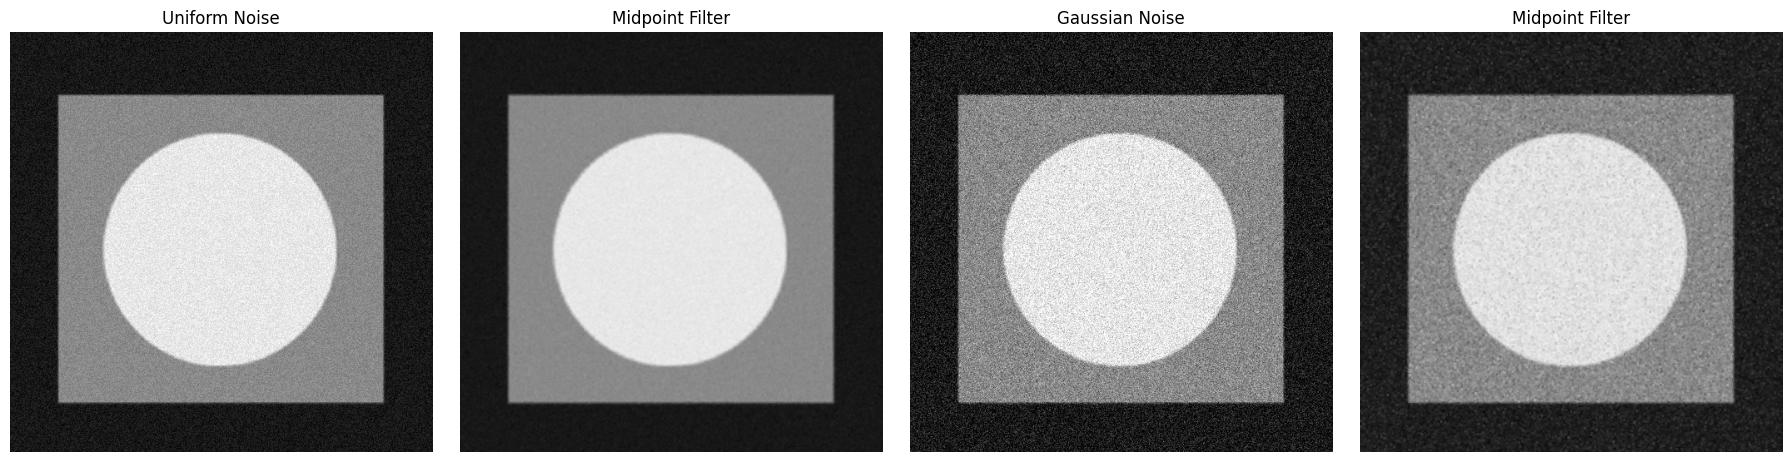

In [17]:
def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)


show([noise_uni, midpoint_filter(noise_uni), noise_gauss, midpoint_filter(noise_gauss)],
     ['Uniform Noise', 'Midpoint Filter', 'Gaussian Noise', 'Midpoint Filter'], size=4.5)

## Comparing all the filters

Every filter (3x3) is applied to each of the four noisy images and scored with
PSNR against the clean image. The best filter for each noise type is marked.

In [18]:
filters = {
    "None (noisy)": lambda im: im,
    "Arithmetic mean": lambda im: cv2.blur(im, (3, 3)),
    "Geometric mean": geometric_mean_filter,
    "Harmonic mean": harmonic_mean_filter,
    "Contra-harmonic Q=1.5": lambda im: contra_harmonic_mean(im, Q=1.5),
    "Contra-harmonic Q=-1.5": lambda im: contra_harmonic_mean(im, Q=-1.5),
    "Median": lambda im: cv2.medianBlur(im, 3),
    "Max": lambda im: cv2.dilate(im, kernel),
    "Min": lambda im: cv2.erode(im, kernel),
    "Midpoint": midpoint_filter,
}

scores = {f: [psnr(img, fn(im)) for im in noisy_images.values()] for f, fn in filters.items()}
best = np.argmax(list(scores.values()), axis=0)

print(f"{'PSNR (dB)':24s}" + "".join(f"{n:>15s}" for n in noisy_images))
for row, (f, vals) in enumerate(scores.items()):
    print(f"{f:24s}" + "".join(f"{v:14.2f}{'*' if best[c] == row else ' '}"
                               for c, v in enumerate(vals)))

PSNR (dB)                      Gaussian  Salt & Pepper    Exponential        Uniform
None (noisy)                     20.87          18.50          25.70          26.88 
Arithmetic mean                  30.01*         27.47          28.20          35.82 
Geometric mean                   24.19          14.18          29.30          33.85 
Harmonic mean                    23.47          13.18          29.84          31.30 
Contra-harmonic Q=1.5            23.33          14.04          26.19          32.34 
Contra-harmonic Q=-1.5           23.04          13.18          30.31          29.36 
Median                           27.71          50.88*         30.15          32.34 
Max                              16.66          11.57          18.79          23.35 
Min                              17.20          13.15          33.47*         22.92 
Midpoint                         27.15          15.63          25.01          37.17*


The table matches the theory:

- **Gaussian noise** is best handled by the **arithmetic mean**. The geometric,
  harmonic and contra-harmonic means do worse here because the noise pushes
  many background pixels to 0, which those filters are sensitive to.
- **Uniform noise** is best handled by the **midpoint** filter (with the
  arithmetic mean close behind): uniform noise has a bounded range, so
  `(max + min) / 2` is a good estimate of the centre.
- **Salt & pepper noise** is best handled by the **median** filter by a wide
  margin (about 51 dB vs 27 dB for the next best). The arithmetic mean helps a
  little, but every other filter scores *below* the unfiltered image because
  they spread the impulses.
- **Exponential noise** is one-sided (it only adds brightness), so the **min**
  filter and the contra-harmonic filter with `Q < 0`, which both favour dark
  values, partly undo the shift and do best.

## Resources

- <https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html>
- <https://docs.opencv.org/4.x/d5/d0f/tutorial_py_gradients.html>
- Gonzalez & Woods, *Digital Image Processing*, Section 5.3: Restoration in the
  Presence of Noise Only—Spatial Filtering